In [1]:
%matplotlib inline
import os
import sys

# Move up one directory level from /notebooks to the workspace root
workspace_root = os.path.abspath(os.path.join(os.getcwd(), ".."))

if workspace_root not in sys.path:
    sys.path.append(workspace_root)

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as nd

import astropy.io.fits as pyfits
import astropy.units as u


import grizli
from grizli import utils
print(f'grizli version: {grizli.__version__}')

import msaexp
import msaexp.spectrum
print(f'msaexp version: {msaexp.__version__}')

BASE_URL = 'https://s3.amazonaws.com/msaexp-nirspec/extractions/'
PATH_TO_FILE = BASE_URL + '{root}/{file}'

from utils.fitting import line_cont_fit
from utils.spectrum_management import (resampling_spectra, weighted_average)


Halpha = {
    'element': r'3H\alpha, [NII]6548, [NII]6583',
    'rest_AA': [6564 * u.AA, 6548 * u.AA, 6583 * u.AA], 
    'sigma': 7.5, 
    'amplitude': [1 * 1e-18, 0.05* 1e-18, 0.07* 1e-18]   # La amplitud inicial es lo unico que cambia si se transforma antes o despues de fittear
}

Sii = {
    'element': r'2[SII]6717, [SII]6731',
    'rest_AA': [6717 * u.AA, 6731 * u.AA], 
    'sigma': 7.5, 
    'amplitude': [0.1* 1e-18, 0.09* 1e-18]  
}

Oiii = {
    'element': r'1[OIII]4364',
    'rest_AA': 4364 * u.AA, 
    'sigma': 7.5, 
    'amplitude': 0.075 * 1e-18  
}

Oiii1 = {
    'element': r'1[OIII]4959',
    'rest_AA': 4959 * u.AA, 
    'sigma': 7.5, 
    'amplitude': 0.35 * 1e-18  
}

Oiii2 = {
    'element': r'1[OIII]5007',
    'rest_AA': 5007 * u.AA, 
    'sigma': 7.5, 
    'amplitude': 1.4 * 1e-18  
}

Hbeta = {
    'element': r'1Hbeta',
    'rest_AA': 4861 * u.AA, 
    'sigma': 7.5, 
    'amplitude': 0.2 * 1e-18  
}

Oii = {
    'element': r'1[OII]3727',
    'rest_AA': 3727 * u.AA, 
    'sigma': 7.5, 
    'amplitude': 0.3 * 1e-18  
}

Oiid = {
    'element': r'2[OII]7322, [OII]7332',
    'rest_AA': [7322 * u.AA, 7332 * u.AA], 
    'sigma': 7.5, 
    'amplitude': [0.075* 1e-18, 0.075* 1e-18]  
}

Oi = {
    'element': r'1[OI]6300',
    'rest_AA': 6300 * u.AA, 
    'sigma': 7.5, 
    'amplitude': 0.04 * 1e-18  
}

lines = [Halpha, Hbeta, Oi, Oii, Oiid, Oiii, Oiii1, Oiii2, Sii]

grizli version: 1.14.2
msaexp version: 0.9.17


https://grizli-cutout.herokuapp.com/nirspec_extractions?file=aurora-gdn02-v4_g395m-f290lp_1914_19848.spec.fits&output=csv
aurora-gdn02-v4_g140m-f100lp_1914_19848.spec.fits (True) 2.9931  grade=3
aurora-gdn02-v4_g235m-f170lp_1914_19848.spec.fits (True) 2.9931  grade=3
aurora-gdn02-v4_g395m-f290lp_1914_19848.spec.fits (True) 2.9933  grade=3
3H\alpha, [NII]6548, [NII]6583


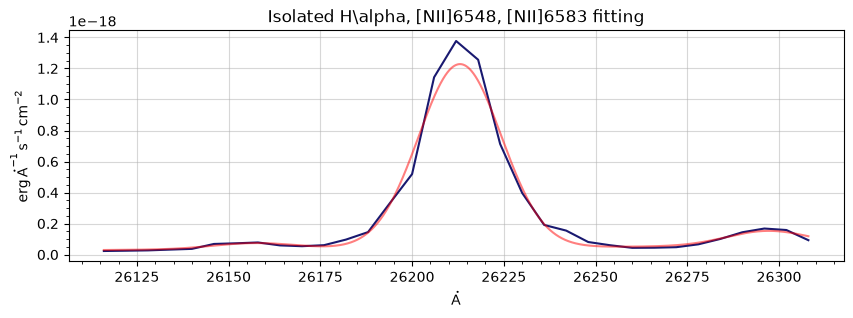

1Hbeta


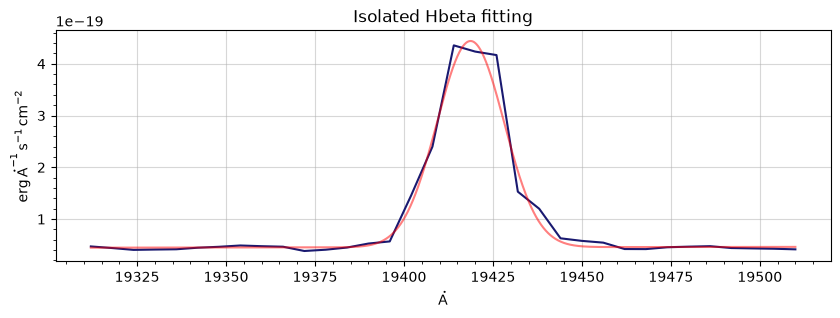

1[OI]6300


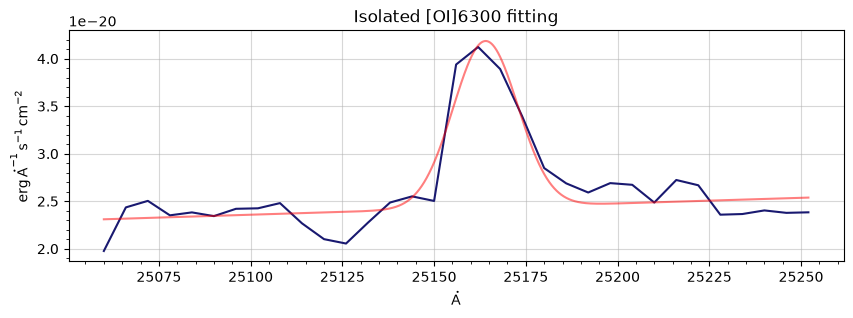

1[OII]3727


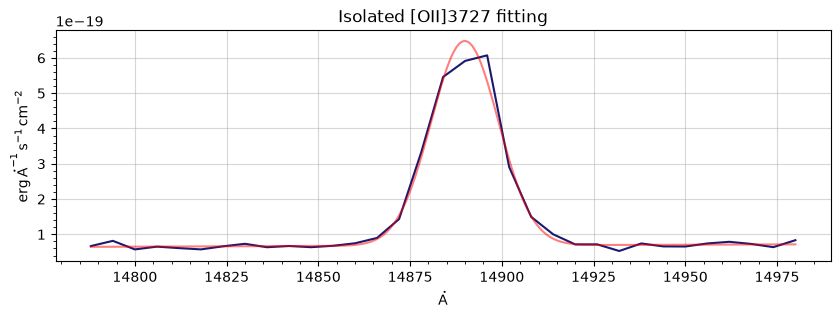

2[OII]7322, [OII]7332


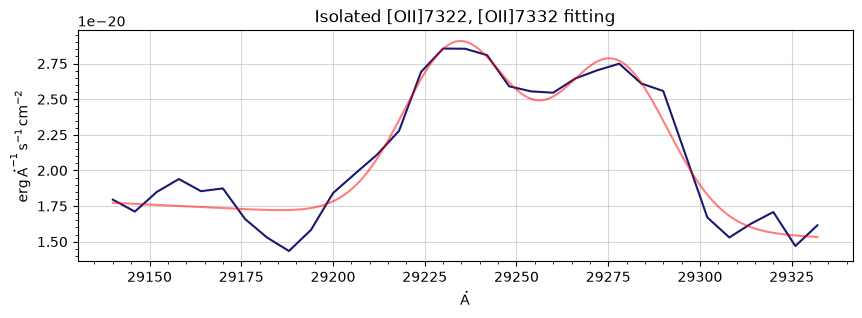

1[OIII]4364


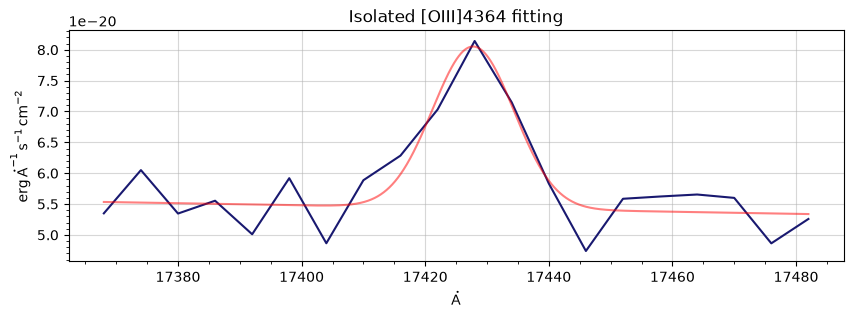

1[OIII]4959


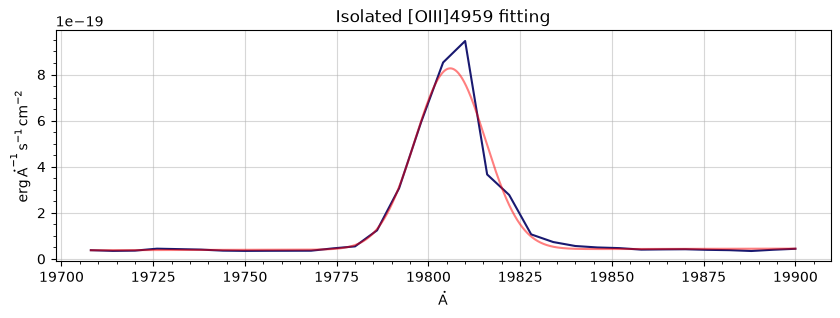

1[OIII]5007


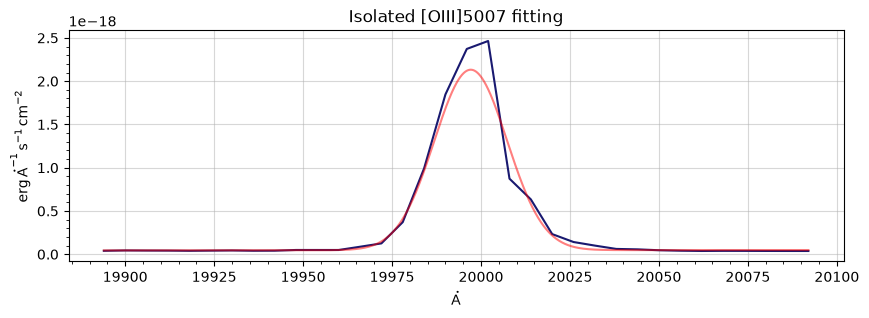

2[SII]6717, [SII]6731


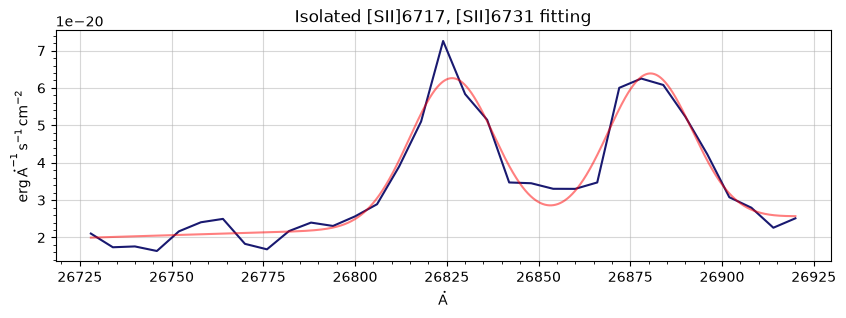

In [2]:
resampled = resampling_spectra("aurora-gdn02-v4_g395m-f290lp_1914_19848.spec.fits") #aurora-gdn02-v4_g235m-f170lp_1914_931951.spec.fits

averaged = weighted_average(resampled)

fits = {}
fluxes = {}

for line in lines:
    optimal, opterrs = line_cont_fit(averaged, line)
    fits[optimal['element']] = [optimal, opterrs]
    if optimal['lines'] == '1':
        fluxes[optimal['element']] = optimal['flux1'] * 1e20
    elif optimal['lines'] == '2':
        fluxes[optimal['element']] = [optimal['flux1'] * 1e20, optimal['flux2'] * 1e20]
    elif optimal['lines'] == '3':
        fluxes[optimal['element']] = [optimal['flux1'] * 1e20, optimal['flux2'] * 1e20, optimal['flux3'] * 1e20]

In [3]:
display(fluxes)

{'H\\alpha, [NII]6548, [NII]6583': [3347.3835425090165,
  109.49632510012015,
  273.2501410429882],
 'Hbeta': 940.1135049026165,
 '[OI]6300': 38.57705052208125,
 '[OII]3727': 1331.7806543659888,
 '[OII]7322, [OII]7332': [45.74500631716715, 43.072280620752075],
 '[OIII]4364': 43.31874827942085,
 '[OIII]4959': 1883.5595386874068,
 '[OIII]5007': 5344.05096967179,
 '[SII]6717, [SII]6731': [114.42487424272966, 113.48159982202479]}

In [4]:
import pyneb as pn

O3 = pn.Atom("O", 3)
O2 = pn.Atom("O", 2)
S2 = pn.Atom("S", 2)

s2_tem_ex = 3.2*1e4 # Chosen by hand (how to use effective collision strengths?)

s2_den = S2.getTemDen(fluxes['[SII]6717, [SII]6731'][0]/fluxes['[SII]6717, [SII]6731'][1], 
                       tem = s2_tem_ex, wave1=6718,wave2=6733)
o3_temp = O3.getTemDen(fluxes['[OIII]4364']/fluxes['[OIII]5007'], 
                       den = s2_tem_ex, wave1=4364,wave2=5007)

print(s2_den)
print(o3_temp)

o2_temp = O2.getTemDen((fluxes['[OII]7322, [OII]7332'][0] + fluxes['[OII]7322, [OII]7332'][1])/fluxes['[OII]3727'], 
                       den = s2_tem_ex, wave1=7327,wave2=3728)

o2_temp_emp = 0.7 * o3_temp + 3000
print(o2_temp)
print(o2_temp_emp)

o3_abun = O3.getIonAbundance(fluxes['[OIII]5007']/fluxes['Hbeta']*100, tem=o3_temp, den=s2_den,
                             wave=5007)
o2_abun = O2.getIonAbundance(fluxes['[OII]3727']/fluxes['Hbeta']*100, tem=o3_temp, den=s2_den,
                             to_eval='3726+3729')


o_abun = o3_abun+o2_abun
o_abun_16,o_abun_50,o_abun_84 = np.percentile(o_abun,(15.8,50,84.2))
# o_abun_log12 = 12+np.log10(o3_abun+o2_abun)

print(f'Stack has 12+log(O/H) = {12+np.log10(o_abun_50):.2f} ({12+np.log10(o_abun_16):.2f}-{12+np.log10(o_abun_84):.2f})')

1054.3921723167202
10277.573857418769
4897.598611664489
10194.301700193137
Stack has 12+log(O/H) = 8.26 (8.26-8.26)


In [ ]:
import pyneb as pn

O3 = pn.Atom("O", 3)
O2 = pn.Atom("O", 2)
S2 = pn.Atom("S", 2)

s2_tem_ex = 1e3 # Chosen by hand (how to use effective collision strengths?)

np.random.seed(1312)
nrand = 1000

sii6717_stack = fluxes['[SII]6717, [SII]6731'][0] + np.random.normal(0,1,nrand)*fits['[SII]6717, [SII]6731'][1]['flux1']*1e20
sii6731_stack = fluxes['[SII]6717, [SII]6731'][1] + np.random.normal(0,1,nrand)*fits['[SII]6717, [SII]6731'][1]['flux2']*1e20
oiii4364_stack = fluxes['[OIII]4364'] + np.random.normal(0,1,nrand)*fits['[OIII]4364'][1]['flux']*1e20
oiii5007_stack = fluxes['[OIII]5007'] + np.random.normal(0,1,nrand)*fits['[OIII]5007'][1]['flux']*1e20
oii3727_stack = fluxes['[OII]3727'] + np.random.normal(0,1,nrand)*fits['[OII]3727'][1]['flux']*1e20
oii7322_stack = fluxes['[OII]7322, [OII]7332'][0] + np.random.normal(0,1,nrand)*fits['[OII]7322, [OII]7332'][1]['flux1']*1e20
oii7332_stack = fluxes['[OII]7322, [OII]7332'][1] + np.random.normal(0,1,nrand)*fits['[OII]7322, [OII]7332'][1]['flux2']*1e20

hbeta_stack = fluxes['Hbeta'] + np.random.normal(0,1,nrand)*fits['Hbeta'][1]['flux'] *1e20



s2_den = S2.getTemDen(sii6717_stack/sii6731_stack, tem = s2_tem_ex, wave1=6716,wave2=6730)

s2den_16,s2den_50,s2den_84 = np.nanpercentile(s2_den,(15.8,50,84.2))

print('Density estimates:')
print(s2den_16,s2den_50,s2den_84)
print('')

o3_temp = O3.getTemDen(oiii4364_stack/oiii5007_stack, 
                       den = s2_den, wave1=4364,wave2=5007)

o3temp_16,o3temp_50,o3temp_84 = np.nanpercentile(o3_temp,(15.8,50,84.2))

print('Te O2+ estimates:')
print(o3temp_16,o3temp_50,o3temp_84)
print('')

o2_temp = O2.getTemDen((oii7322_stack + oii7332_stack)/oii3727_stack, 
                       den = s2_den, wave1=7327,wave2=3728)

o2_temp_emp = 0.7 * o3_temp + 3000

o2temp_16,o2temp_50,o2temp_84 = np.nanpercentile(o2_temp,(15.8,50,84.2))

print('Te O+ estimates:')
print(o2temp_16,o2temp_50,o2temp_84)
print('')

o2tempemp_16,o2tempemp_50,o2tempemp_84 = np.nanpercentile(o2_temp_emp,(15.8,50,84.2))

print('Te O+ empirical estimates:')
print(o2tempemp_16,o2tempemp_50,o2tempemp_84)
print('')


o3_abun = O3.getIonAbundance(oiii5007_stack/hbeta_stack*100, tem=o3_temp, den=s2_den,
                             wave=5007)
o2_abun = O2.getIonAbundance(oii3727_stack/hbeta_stack*100, tem=o2_temp_emp, den=s2_den,
                             to_eval='3726+3729')

o_abun = o3_abun+o2_abun
o_abun_16,o_abun_50,o_abun_84 = np.nanpercentile(o_abun,(15.8,50,84.2))
# o_abun_log12 = 12+np.log10(o3_abun+o2_abun)

print(f'Stack has 12+log(O/H) = {12+np.log10(o_abun_50):.2f} ({12+np.log10(o_abun_16):.2f}-{12+np.log10(o_abun_84):.2f})')



Density estimates:
132.2160521833825 206.44960463914194 303.9195382313198

Te O2+ estimates:
10119.333069360917 10730.873267288294 11338.671705207878

Te O+ estimates:
nan nan nan

Te O+ empirical estimates:
10083.533148552642 10511.611287101805 10937.070193645513

Stack has 12+log(O/H) = 8.20 (8.12-8.28)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pyneb as pn
from astropy.io import ascii

np.random.seed(1216)

read Tino's stack table
lines = ascii.read('tino_stack_fluxes.csv')

# generate 1000 fluxes per line consistent with flux uncertainty
nrand = 1000
oii3726_stack = lines['flux'][0] + np.random.normal(0,1,nrand)*lines['flux_err'][0]
oii3729_stack = lines['flux'][1] + np.random.normal(0,1,nrand)*lines['flux_err'][1]
oiii4363_stack = lines['flux'][2] + np.random.normal(0,1,nrand)*lines['flux_err'][2]
hb_stack = lines['flux'][3] + np.random.normal(0,1,nrand)*lines['flux_err'][3]
oiii5007_stack = lines['flux'][4] + np.random.normal(0,1,nrand)*lines['flux_err'][4]
ha_stack = lines['flux'][5] + np.random.normal(0,1,nrand)*lines['flux_err'][5]

# define O+ and O++ ions for PyNeb calculations
O2 = pn.Atom("O", 2)
O3 = pn.Atom("O", 3)

# calculate density from [OII] doublet ratio
o2_den = O2.getTemDen(oii3726_stack/oii3729_stack,tem=1.25e4,wave1=3726,wave2=3729)
o2_den[np.isnan(o2_den)] = 10

# calculate temperature from [OIII] auroral-to-nebular ratio
o3_temp = O3.getTemDen(oiii4363_stack/oiii5007_stack,den=o2_den,wave1=4363,wave2=5007)
o3_temp[np.isnan(o3_temp)] = 25119 # max temp allowed

# calculate ionic abundances
o3_abun = O3.getIonAbundance(oiii5007_stack/hb_stack*100, tem=o3_temp, den=o2_den,
                             wave=5007)
o2_abun = O2.getIonAbundance((oii3726_stack+oii3729_stack)/hb_stack*100, tem=o3_temp, den=o2_den,
                             to_eval='3726+3729')
o_abun = o3_abun+o2_abun
o_abun_16,o_abun_50,o_abun_84 = np.percentile(o_abun,(15.8,50,84.2))
# o_abun_log12 = 12+np.log10(o3_abun+o2_abun)

print(f'Stack has 12+log(O/H) = {12+np.log10(o_abun_50):.2f} ({12+np.log10(o_abun_16):.2f}-{12+np.log10(o_abun_84):.2f})')



test on Rogers+24 D40 values (relative to Hb)
oiii4363_D40 = 0.081
oiii4959_D40 = 2.014
oiii5007_D40 = 6.002
hb_D40 = 1.0
o2_den_D40 = 73

o3_temp_D40 = O3.getTemDen(oiii4363_D40/oiii5007_D40,den=o2_den_D40,wave1=4363,wave2=5007)

o3_abun_D40 = O3.getIonAbundance(oiii5007_D40/hb_D40*100, tem=o3_temp_D40, den=o2_den_D40,
                             wave=5007)
print(f'D40 has 12+log(O++/H) = {12+np.log10(o3_abun_D40):.2f}')

D40 has 12+log(O++/H) = 7.99


In [16]:
import pyneb as pn

O3 = pn.Atom("O", 3)
O2 = pn.Atom("O", 2)
S2 = pn.Atom("S", 2)

np.random.seed(1312)
nrand = 1000

sii6717_stack = fluxes['[SII]6717, [SII]6731'][0] + np.random.normal(0,1,nrand)*fits['[SII]6717, [SII]6731'][1]['flux1']*1e20
sii6731_stack = fluxes['[SII]6717, [SII]6731'][1] + np.random.normal(0,1,nrand)*fits['[SII]6717, [SII]6731'][1]['flux2']*1e20
oiii4364_stack = fluxes['[OIII]4364'] + np.random.normal(0,1,nrand)*fits['[OIII]4364'][1]['flux']*1e20
oiii5007_stack = fluxes['[OIII]5007'] + np.random.normal(0,1,nrand)*fits['[OIII]5007'][1]['flux']*1e20
oii3727_stack = fluxes['[OII]3727'] + np.random.normal(0,1,nrand)*fits['[OII]3727'][1]['flux']*1e20
oii7322_stack = fluxes['[OII]7322, [OII]7332'][0] + np.random.normal(0,1,nrand)*fits['[OII]7322, [OII]7332'][1]['flux1']*1e20
oii7332_stack = fluxes['[OII]7322, [OII]7332'][1] + np.random.normal(0,1,nrand)*fits['[OII]7322, [OII]7332'][1]['flux2']*1e20

hbeta_stack = fluxes['Hbeta'] + np.random.normal(0,1,nrand)*fits['Hbeta'][1]['flux'] *1e20

sii_ratio = sii6717_stack / sii6731_stack

print("Your [S II] ratio percentiles:")
print(np.nanpercentile(sii_ratio, [16, 50, 84]))

for T in [1e4, 1.5e4, 2e4]:
    ne = S2.getTemDen(
        sii_ratio,
        tem=T,
        wave1=6716,
        wave2=6731
    )
    print(
        f"T = {T:.0f} K:",
        np.nanpercentile(ne, [16, 50, 84])
    )

print("Observed [S II] ratio:",
      np.nanmedian(sii6717_stack / sii6731_stack))

print("Low-density limit:",
      S2.getLowDensRatio(wave1=6716, wave2=6731))

print("High-density limit:",
      S2.getHighDensRatio(wave1=6716, wave2=6731))

print("Atomic data:")
S2.printSources()

Your [S II] ratio percentiles:
[0.91843414 1.0138166  1.11567728]
T = 10000 K: [440.03459123 673.73367161 983.6138472 ]
T = 15000 K: [ 502.86842274  778.87446301 1144.00515076]
T = 20000 K: [ 551.93995837  865.09099264 1275.44691824]
Observed [S II] ratio: 1.0138166046219654
Low-density limit: 1.4549437994634162
High-density limit: 0.44998411328841936
Atomic data:
S2: All A-values for levels 1-5: Rynkun, P., Gaigalas, G., & Jonsson, P. 2019, Astronomy and Astrophysics, 623, A155: 
S2: Energy levels: 
    Ref. 7237 of NIST 2014 (try this: http://physics.nist.gov/cgi-bin/ASBib1/get_ASBib_ref.cgi?db=el&db_id=7237&comment_code=&element=S&spectr_charge=2&): 
S2: collision strengths: Tayal & Zatsarinny 2010, ApJ 188, 32: 
